<a href="https://colab.research.google.com/github/ldelia22/16.32-Redes-Neuronales-en-Bioingenieria-TP4/blob/main/TP4_CNN_Skin_DELIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

### Datos
El dataset no se sube al repositorio. Si la carpeta `data/Split_smol` no está (por ejemplo, en un entorno recién creado), la celda siguiente descarga el repositorio de la cátedra y usa su carpeta `data/`. Si ya está, no hace nada.

In [ ]:
import os, subprocess
if not os.path.isdir("data/Split_smol"):
    if not os.path.isdir("_repo_catedra"):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "https://github.com/cselmo/CNN-en-Skin-Dataset", "_repo_catedra"], check=True)
    os.symlink("_repo_catedra/data", "data")
print("Clases en data/Split_smol/train:", len(os.listdir("data/Split_smol/train")))

Clases en data/Split_smol/train: 9


In [ ]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.1+cu130


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [ ]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 10s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


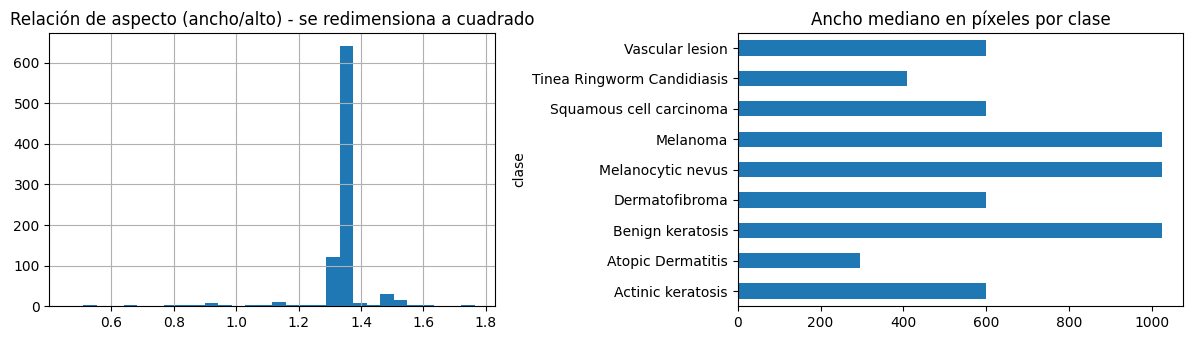

In [ ]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

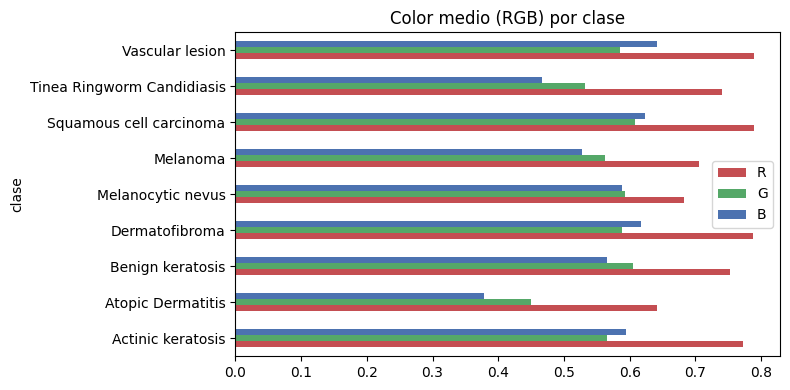

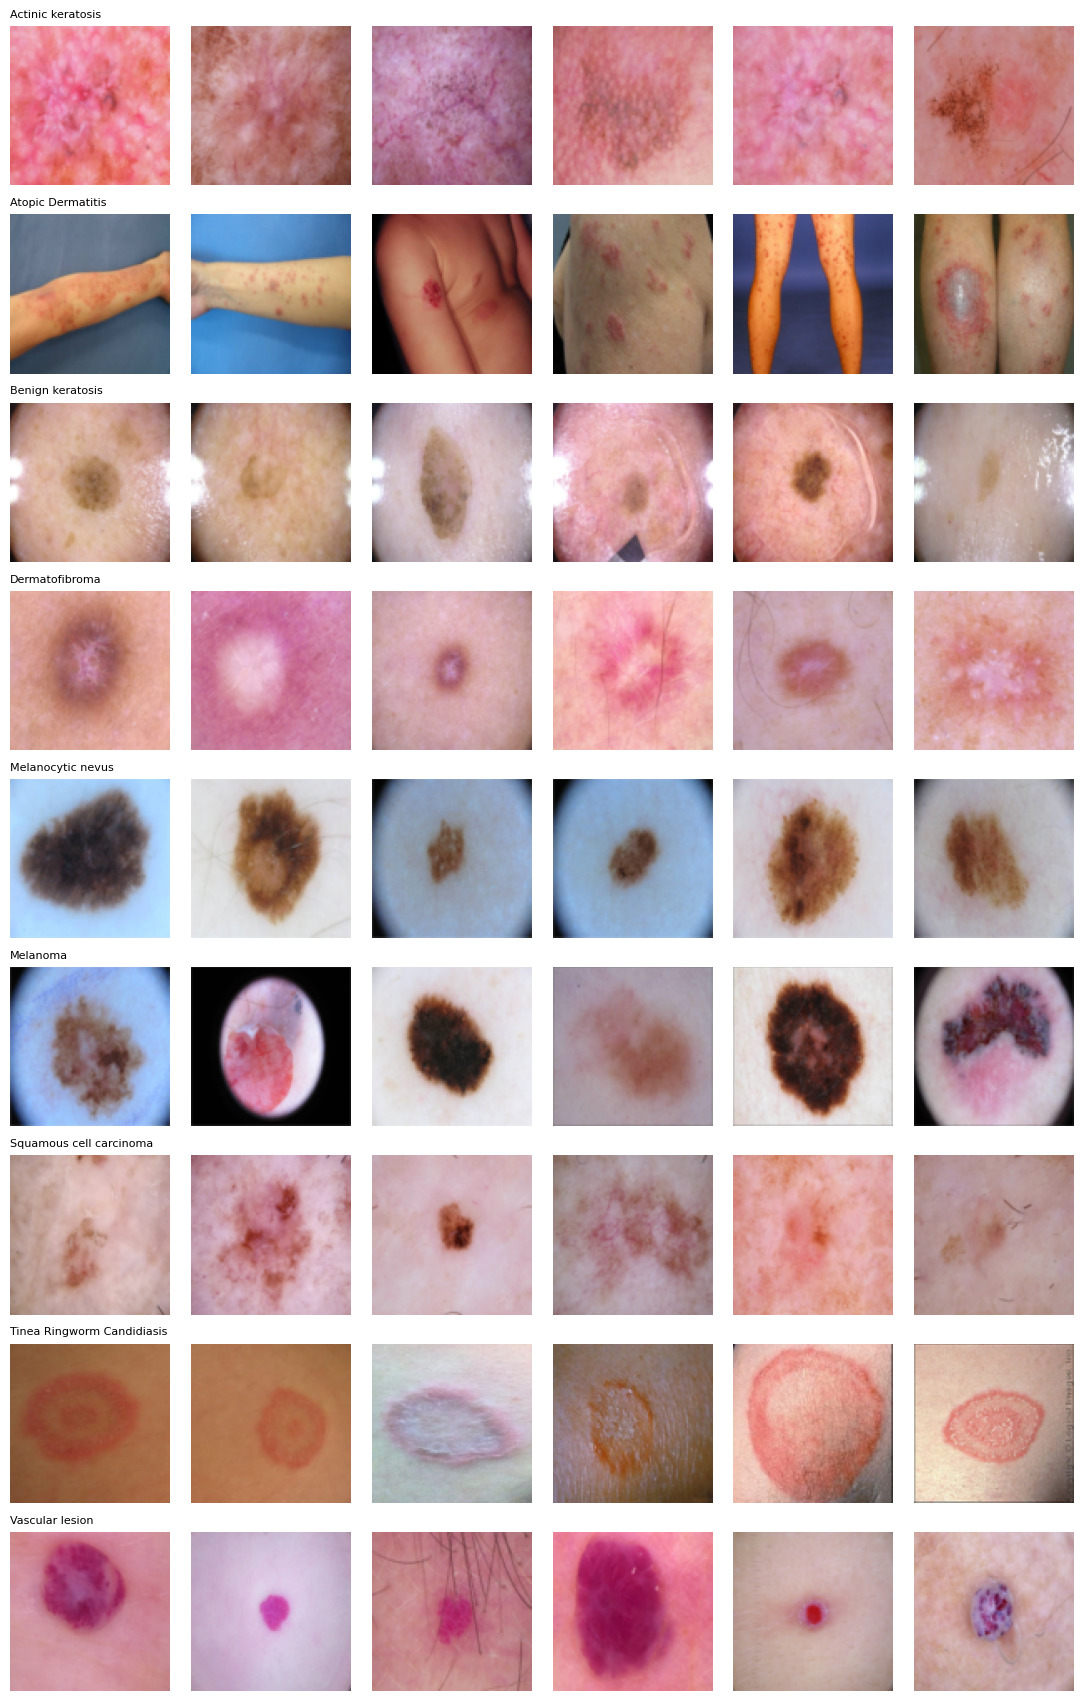

In [ ]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [ ]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?

**Respuestas**

La corrida se hizo en GPU (`Dispositivo: cuda`), por lo que los tiempos son menores que los de referencia en CPU. No se modificó ninguna constante de la sección 0, y la única celda agregada es "Datos", que descarga el dataset si no está disponible.

1. El desbalance es moderado. Siete clases tienen 100 imágenes (80 en `train/` y 20 en `val/`), Atopic Dermatitis tiene 102 y Tinea Ringworm Candidiasis 76. Al eliminar los duplicados el desbalance aumenta, porque Atopic Dermatitis queda con 80 imágenes y Tinea con 64, y en el nuevo split tienen 48 y 38 imágenes de train frente a 60 de las demás clases. La partición original tenía 20 imágenes de validación por clase y no incluía test, y además esa validación no era independiente del train, como se explica en el punto 3.

2. La resolución prácticamente identifica la clase. Todas las imágenes de Atopic Dermatitis son de 294×222, todas las de Actinic keratosis, Dermatofibroma, Squamous cell carcinoma y Vascular lesion son de 600×450, el 74 % de Benign keratosis es de 1024×764, Melanocytic nevus y Melanoma son mayormente de 1024×768 y las de Tinea caen todas en otras resoluciones. Los ejemplos muestran que Atopic Dermatitis y Tinea no son imágenes dermatoscópicas sino fotos clínicas, con brazos, piernas y fondos de tela azul, y por eso Atopic Dermatitis tiene el color medio más oscuro y con menos componente azul y verde. Otras clases presentan marcas propias del equipo, como la viñeta circular negra en nevus y melanoma o los reflejos de flash a los costados en Benign keratosis. El riesgo es que el modelo aprenda a reconocer el origen de la imagen (la resolución original, que deja rastros de nitidez al redimensionar, el tipo de foto o el fondo) en lugar de la lesión, un atajo que funciona en este dataset pero que no generaliza.

3. Se encontraron 34 grupos de imágenes idénticas según el MD5, todos pertenecientes a dos clases, 22 de Atopic Dermatitis y 12 de Tinea. Ninguno tiene etiquetas en conflicto, y el hash perceptual no detectó casi-duplicados distintos de los idénticos (encontró 34 pares, que son los mismos). De esos grupos, 33 estaban repetidos entre `train/` y `val/`, es decir que 33 de las 181 imágenes de validación (18 %) ya estaban en train, lo que abarca casi toda la validación de esas dos clases. Si no se eliminaran, el modelo podría memorizar esas imágenes y la `val_acc` quedaría inflada, sobre todo en Atopic Dermatitis y Tinea, sin medir realmente la capacidad de generalización.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [ ]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

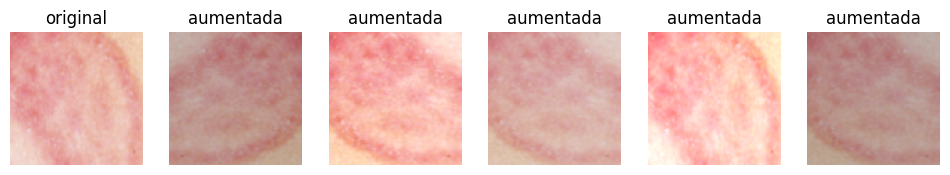

In [ ]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [ ]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [ ]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.

**Respuestas**

Las respuestas se refieren a la CNN base con una imagen de 64×64 y a la tabla de la sección 4.1.

1. Con kernel 3, `padding=kernel // 2` vale 1, es decir que se agrega un borde de un píxel con ceros y la salida conserva el alto y el ancho de la entrada. En la tabla se ve que cada `Conv2d` mantiene el tamaño espacial, de (3, 64, 64) a (16, 64, 64), de (16, 32, 32) a (32, 32, 32) y de (32, 16, 16) a (64, 16, 16). Con `padding=0`, cada convolución de kernel 3 perdería un píxel en cada borde (64 pasaría a 62), los tamaños dejarían de ser potencias de 2 y `fs = size // 2 ** n_blocks` ya no coincidiría con la entrada real de la capa `Linear`.

2. `MaxPool2d(2)` toma el máximo de cada bloque de 2×2, de modo que divide por 2 el alto y el ancho sin cambiar la cantidad de canales. En la tabla se observa el paso de (16, 64, 64) a (16, 32, 32), de (32, 32, 32) a (32, 16, 16) y de (64, 16, 16) a (64, 8, 8). Lo que conserva es la activación más fuerte de cada zona, o sea, si el patrón que detecta el filtro aparece en esa zona, aunque se pierde su posición exacta. Los tres pooling dividen el lado por $2^3 = 8$, y por eso `fs = 64 // 8 = 8` es el lado del último mapa.

3. La segunda `Conv2d` (de 16 a 32 canales, kernel 3 y sin sesgo) tiene $3 \times 3 \times 16 \times 32 = 4608$ parámetros, lo mismo que indica la tabla. La primera `Linear` de la cabeza recibe el mapa aplanado de $64 \times 8 \times 8 = 4096$ valores y tiene 128 salidas, por lo que tiene $4096 \times 128 + 128 = 524.416$ parámetros, también en coincidencia con la tabla. La capa `Linear` domina el total, ya que reúne 524.416 de los 549.273 parámetros (95,5 %), mientras que las tres convoluciones suman 23.472 (4,3 %). La diferencia se debe a que la convolución usa un mismo filtro chico en todas las posiciones, mientras que la capa densa conecta cada valor del mapa con cada una de sus unidades.

4. La BatchNorm resta la media del batch en cada canal, de modo que cualquier sesgo constante que sume la convolución se cancela en esa resta. El desplazamiento lo aporta el parámetro $\beta$ de la BatchNorm, que se aprende. Por eso cada `BatchNorm2d` tiene 2 parámetros por canal, $\gamma$ y $\beta$ (32 para 16 canales), mientras que la media y la varianza móviles no son parámetros entrenables.

5. Cada bloque divide el área por 4 con el pooling y duplica la cantidad de canales (16, 32 y 64). Así, el costo de cada convolución, proporcional al producto del alto, el ancho y los canales de entrada y de salida, se mantiene parecido entre bloques, y el volumen de activaciones se reduce a la mitad en cada uno. Además, al bajar la resolución cada posición resume una zona más grande con patrones más complejos, que combinan los de la capa anterior, y hacen falta más canales para representarlos.

6. El campo receptivo se calcula empezando con $r = 1$ y un salto $j = 1$. Cada convolución suma $(k-1)\,j$ y cada pooling suma $j$ y duplica el salto. En el primer bloque la convolución lleva $r$ a $1 + 2 = 3$ y el pooling a $3 + 1 = 4$, con $j = 2$. En el segundo, la convolución lo lleva a $4 + 2\cdot2 = 8$ y el pooling a $8 + 2 = 10$, con $j = 4$. En el tercero, la convolución lo lleva a $10 + 2\cdot4 = 18$. Esto significa que cada unidad de la última convolución ve una zona de 18×18 píxeles, el 28 % del lado de una imagen de 64 px. Esa zona alcanza para bordes y texturas locales, pero no para la forma global de la lesión, ya que la asimetría o el contorno completo solo se pueden integrar en la capa `Linear` de la cabeza, que recibe todas las posiciones a la vez.

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 10 | val_acc 0.645 | train_acc 0.804 | 0.16 s/época | total 11s


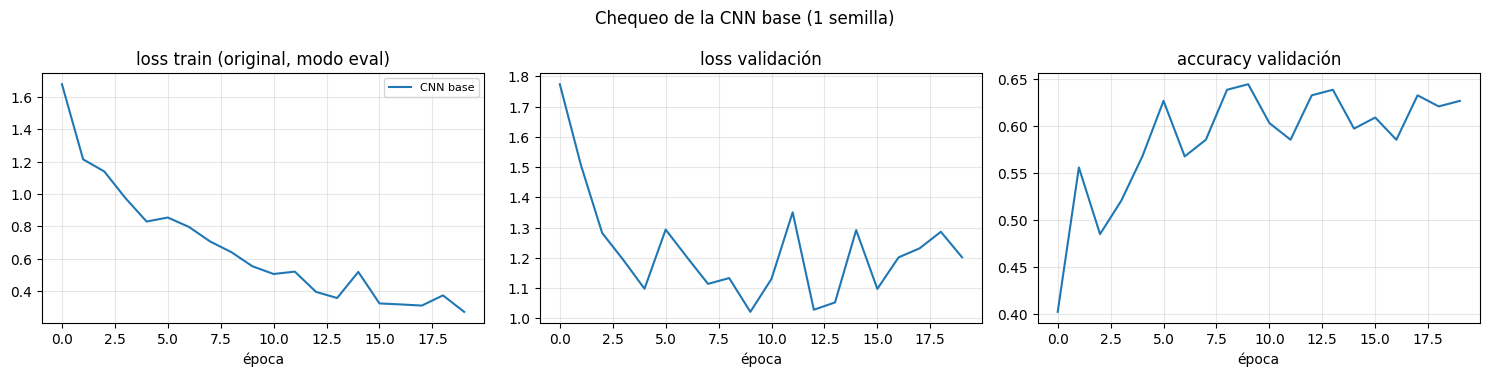

In [ ]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.0338,0.4346,0.0605
1,MLP 64px,6358793,0.5247,0.0433,0.7042,0.1796,6.6667,0.0587,0.4372,0.0874
2,CNN 32px,156057,0.6450,0.0211,0.8393,0.1943,9.3333,0.0561,0.5970,0.0480
3,CNN 64px,549273,0.6233,0.0314,0.7530,0.1297,10.0000,0.0907,0.5700,0.0533


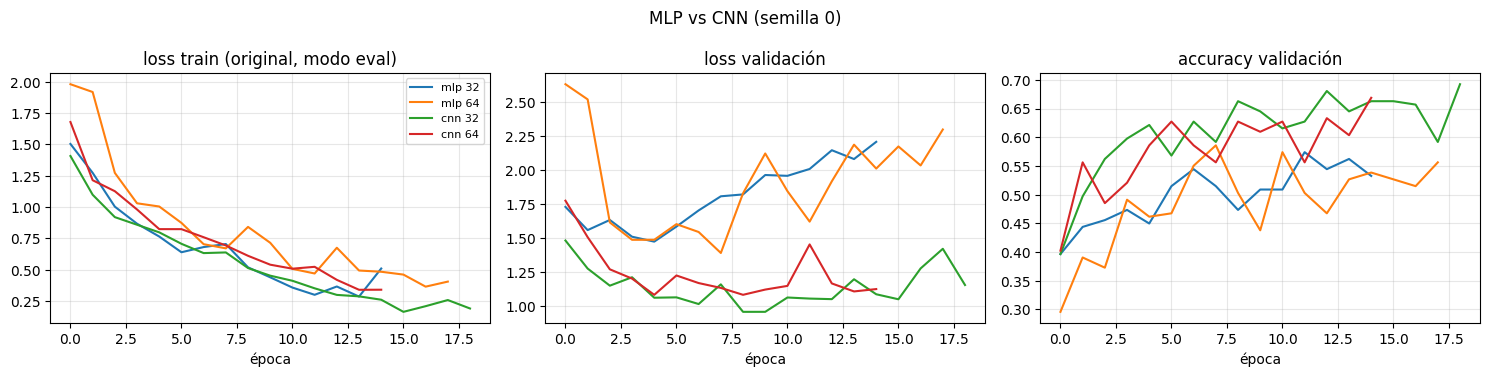

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [ ]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
display(pd.DataFrame(rows).round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?

**Respuestas**

1. La tabla resume la comparación con 3 semillas. El error estándar de la validación es de ≈ 0.038 con 169 imágenes.

   | | Parámetros | val_acc | Brecha | Mejor época | s/época |
   |---|---|---|---|---|---|
   | MLP 32 px | 1.640.201 | 0.495 ± 0.039 | 0.243 | 5.0 | 0.034 |
   | MLP 64 px | 6.358.793 | 0.525 ± 0.043 | 0.180 | 6.7 | 0.059 |
   | CNN 32 px | 156.057 | 0.645 ± 0.021 | 0.194 | 9.3 | 0.056 |
   | CNN 64 px | 549.273 | 0.623 ± 0.031 | 0.130 | 10.0 | 0.091 |

   La CNN supera a la MLP por 15 puntos a 32 px y por 10 puntos a 64 px. Esas diferencias superan el desvío entre semillas y equivalen a 3.9 y 2.6 errores estándar, por lo que son reales. La CNN además sobreajusta menos, con una brecha menor en las dos resoluciones, y lo logra con entre 10 y 12 veces menos parámetros. Tarda algo más por época, porque cada filtro se aplica en todas las posiciones de la imagen, y converge más tarde (épocas 9 y 10 frente a 5 a 7). La MLP llega antes a su mejor validación y empieza a sobreajustar enseguida, con una loss de validación que sube desde la época 3 a 5.

2. La primera capa de la MLP conecta cada valor de entrada con 512 unidades. A 32 px tiene $3 \cdot 32 \cdot 32 \cdot 512 + 512 = 1.573.376$ parámetros (el 96 % del total), a 64 px tiene $3 \cdot 64 \cdot 64 \cdot 512 + 512 = 6.291.968$ y a 224 px tendría $3 \cdot 224 \cdot 224 \cdot 512 + 512 = 77.070.848$, una cantidad desproporcionada para 506 imágenes de train. La convolución cambia esta situación gracias a dos propiedades. Por la conectividad local, cada salida depende solo de una vecindad de 3×3, y por los pesos compartidos, el mismo filtro se usa en todas las posiciones. Por eso la primera convolución tiene 432 parámetros sin importar el tamaño de la imagen, y solo la capa `Linear` de la cabeza crece con la resolución.

3. Con traslaciones de ±4 px a 32 px y de ±8 px a 64 px, la MLP pierde 6.1 y 8.7 puntos y la CNN 4.8 y 5.3. La CNN se degrada menos, como predice la teoría, ya que la convolución es equivariante a las traslaciones y el max-pooling aporta cierta invarianza local. En términos absolutos la diferencia es de 1 a 3 puntos, menor que el error estándar, aunque en términos relativos la MLP pierde el 12 % y el 17 % de su accuracy y la CNN el 7 % y el 9 %, aproximadamente la mitad. El resultado es consistente con la teoría, pero con este tamaño de validación no alcanza para afirmarlo. Además, la CNN no es completamente invariante, porque su cabeza aplana el mapa de 8×8 y asigna un peso distinto a cada posición, y un desplazamiento de 8 px mueve todo el contenido una celda en ese mapa. A esto se suma que la traslación circular (`torch.roll`) introduce un borde artificial donde la imagen se une consigo misma.

4. La media y el desvío de cada canal se calcularon solo con las imágenes de train, con una media de [0.743, 0.572, 0.565] y un desvío de [0.162, 0.164, 0.186] a 64 px, y con esos valores se normalizan train, validación y test. Calcularlos con todas las imágenes filtraría información de validación y test. Sin normalizar, todas las entradas estarían entre 0 y 1, con una media alta en el canal rojo, y los gradientes de todos los pesos que entran a una misma unidad de la primera capa tendrían el mismo signo, lo que haría la optimización más lenta e inestable.

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6292,0.0155,0.8063,0.1771,12.3333,0.0736,1.6476
1,2 bloques,8,1055001,0.6213,0.0269,0.8030,0.1817,12.3333,0.0661,1.4677
2,4 bloques,38,361113,0.6548,0.0422,0.7747,0.1199,12.3333,0.0856,1.9102
3,kernel 5,32,591001,0.5680,0.0269,0.7859,0.2179,15.0000,0.0845,2.1087
4,kernel 7,46,653593,0.5799,0.0167,0.7266,0.1467,16.3333,0.1113,2.9263
5,8 filtros,18,269521,0.6272,0.0302,0.8557,0.2285,10.6667,0.0692,1.4318
6,32 filtros,18,1143337,0.6075,0.0322,0.8024,0.1949,15.0000,0.1135,2.8405
7,32 px,18,156057,0.6351,0.0266,0.8221,0.1870,9.3333,0.0612,1.1967
8,96 px,18,1204633,0.5819,0.0311,0.7740,0.1922,15.0000,0.1167,2.9177


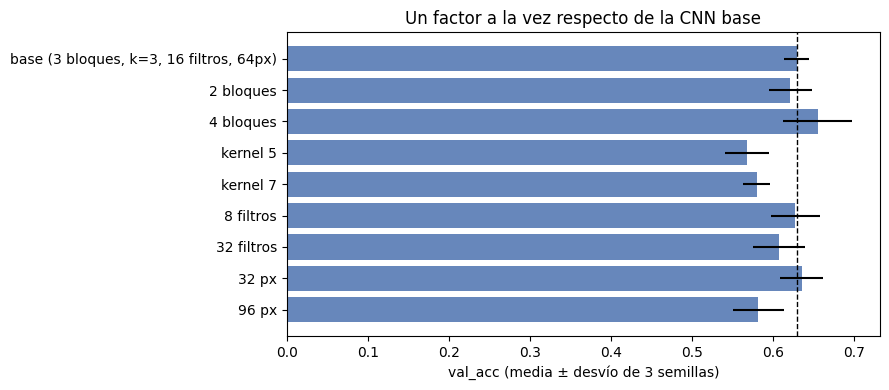

In [ ]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?

**Respuestas**

1. La CNN base obtiene 0.629 ± 0.016 y el error estándar de la validación es de ≈ 0.037. La tabla siguiente ordena las variantes según su diferencia con la base.

   | Variante | val_acc | Diferencia con la base |
   |---|---|---|
   | kernel 5 | 0.568 ± 0.027 | −6.1 |
   | kernel 7 | 0.580 ± 0.017 | −4.9 |
   | 96 px | 0.582 ± 0.031 | −4.7 |
   | 4 bloques | 0.655 ± 0.042 | +2.6 |
   | 32 px | 0.635 ± 0.027 | +0.6 |
   | 8 filtros | 0.627 ± 0.030 | −0.2 |
   | 2 bloques | 0.621 ± 0.027 | −0.8 |
   | 32 filtros | 0.608 ± 0.032 | −2.2 |

   Las únicas diferencias que superan el desvío entre semillas son las caídas con kernel 5, kernel 7 y 96 px, y aun así quedan apenas por encima de un error estándar. La mejora con 4 bloques (+2.6) es menor que su propio desvío (0.042) y que el error estándar, por lo que no puede afirmarse. Los demás cambios (2 bloques, 8 o 32 filtros y 32 px) quedan dentro del ruido. Un indicio adicional del tamaño del ruido es que la CNN base aparece dos veces, con la misma configuración y las mismas semillas, y dio 0.623 ± 0.031 en la sección 5 y 0.629 ± 0.016 en esta sección. El notebook fija las semillas pero no fuerza algoritmos deterministas en la GPU, de modo que una misma configuración no produce exactamente los mismos números en dos ejecuciones, y eso agrega variación.

2. El campo receptivo pasa de 8 px con 2 bloques a 18 con 3 y 38 con 4, y llega a 32 y 46 px con kernels de 5 y 7. Detectar bordes y texturas de la lesión requiere un campo receptivo chico, pero evaluar la asimetría o la forma global requiere abarcar buena parte de la imagen, por lo que se esperaba que agregar bloques o agrandar el kernel resultara beneficioso. Agregar un bloque va en esa dirección (+2.6, sin significancia) y además reduce la cantidad de parámetros (361.113 frente a 549.273), porque el mapa final queda de 4×4 y la capa `Linear` se achica, con un costo por época apenas mayor (0.086 s frente a 0.074 s). Agrandar el kernel, en cambio, empeora el resultado (−6.1 puntos con kernel 5 y −4.9 con kernel 7) y resulta más caro, con 0.111 s por época con kernel 7. Como esas caídas superan apenas un error estándar, el experimento no permite identificar la causa. Para ampliar el campo receptivo, agregar capas con kernels chicos fue más eficiente que agrandar el kernel.

3. Como el mapa final tiene lado `size // 8`, los parámetros de la capa `Linear` crecen con el cuadrado de la resolución. Son $64 \cdot 4 \cdot 4 \cdot 128 + 128 = 131.200$ a 32 px, 524.416 a 64 px y $64 \cdot 12 \cdot 12 \cdot 128 + 128 = 1.179.776$ a 96 px. A 96 px hay más detalle disponible, pero también más parámetros para solo 506 imágenes, mayor costo de cómputo (0.117 s por época frente a 0.074 s) y un campo receptivo que cubre apenas el 19 % del lado de la imagen (18/96), frente al 56 % a 32 px. El resultado obtenido (32 px ≈ 64 px > 96 px) sugiere que con este dataset no se aprovecha el detalle fino. El límite del experimento es que, con tan pocas imágenes, el riesgo de sobreajuste crece con la resolución y puede ocultar cualquier ganancia de información, y que las imágenes provienen de resoluciones originales muy distintas según la clase.

4. Con un diseño que cambia un factor a la vez no se pueden evaluar las interacciones, ya que un factor que no ayuda por sí solo podría ayudar combinado con otro (por ejemplo, 4 bloques a 96 px recuperarían campo receptivo relativo). Tampoco se pueden distinguir diferencias de pocos puntos con 3 semillas, una sola partición y 169 imágenes de validación, ni asegurar que el orden observado se mantenga con otra partición o con más datos.

## 7. Data augmentation
Con ~60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6292,0.0155,0.7945,0.1653,1.0054,12.0000,0.0737,1.6285
1,flips,1518,0.6055,0.0402,0.7312,0.1257,1.0827,6.0000,0.2188,3.4966
2,flips+rot90,1518,0.6529,0.0056,0.8564,0.2035,1.0507,11.3333,0.2173,4.6327
3,flips+rot90+color,1518,0.6252,0.0366,0.7497,0.1244,1.0466,7.3333,0.2146,3.7231


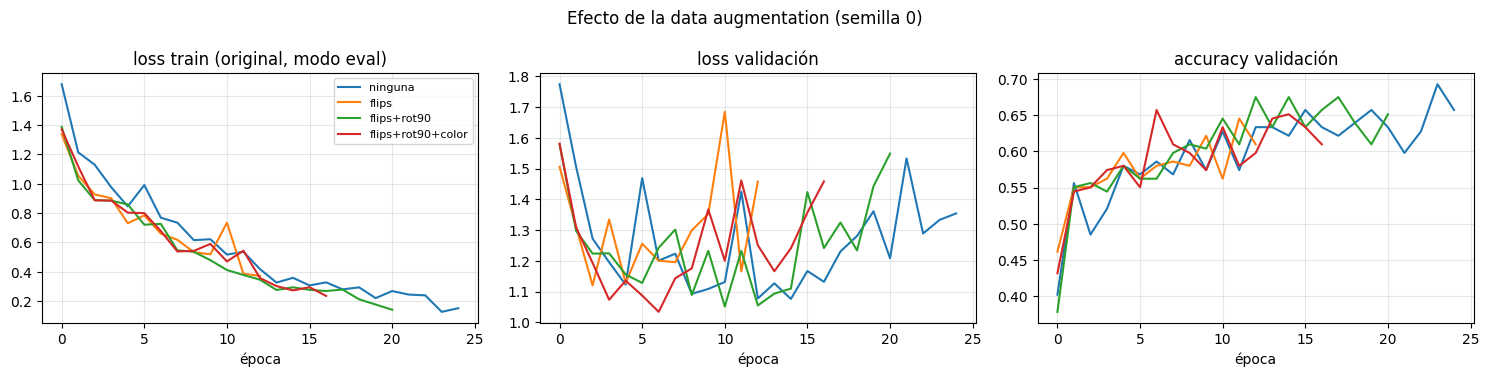

In [ ]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?

**Respuestas**

1. Sin augmentation, en la mejor época (la 12 en promedio) la accuracy de train es 0.795 y la de validación 0.629, lo que da una brecha de 16.5 puntos. En la curva de la semilla 0 sin augmentation (el eje empieza en 0), la loss de train baja de forma continua, de 1.7 a ~0.15 en la última época. La de validación baja hasta ~1.1 en la época 9, oscila con picos, alcanza su mínimo (~1.07) en la época 15 y a partir de ahí sube hasta ~1.5 en la 22, mientras el modelo sigue ajustando el train. El early stopping, con paciencia 10, corta en la época 25, diez épocas después del mínimo, y restaura los pesos de la época 15.

2. La tabla resume el efecto de cada nivel de augmentation.

   | Augmentation | val_acc | Brecha | val_loss | Mejor época | s/época | Tiempo total |
   |---|---|---|---|---|---|---|
   | ninguna | 0.629 ± 0.016 | 0.165 | 1.005 | 12.0 | 0.074 | 1.6 s |
   | flips | 0.606 ± 0.040 | 0.126 | 1.083 | 6.0 | 0.219 | 3.5 s |
   | flips+rot90 | 0.653 ± 0.006 | 0.204 | 1.051 | 11.3 | 0.217 | 4.6 s |
   | flips+rot90+color | 0.625 ± 0.037 | 0.124 | 1.047 | 7.3 | 0.215 | 3.7 s |

   Los flips y la combinación con color reducen la brecha (de 0.165 a ~0.125), es decir que el modelo memoriza menos el train original, mientras que flips+rot90 la aumenta (0.204) porque ajusta mejor el train. Ningún nivel reduce la val_loss respecto de no aumentar. La mejor época baja con flips y con color (6.0 y 7.3 frente a 12.0) y se mantiene con flips+rot90 (11.3), pero como cada época con augmentation tiene unas 3 veces más pasos (1.518 imágenes frente a 506), en cantidad de actualizaciones ninguna variante converge antes que sin aumentar. Ninguna de las mejoras supera el ruido, ya que la mayor (flips+rot90, +2.4 puntos) es menor que el error estándar de 0.037. Cada época tarda unas 3 veces más (de 0.07 a 0.22 s) porque el train pasa de 506 a 1.518 imágenes, las originales más `AUG_COPIES = 2` copias, y el tiempo total se duplica o triplica.

3. Desde el punto de vista dermatológico, los flips y las rotaciones de 90° tienen sentido, porque una lesión observada con el dermatoscopio no tiene una orientación privilegiada y su clase no cambia al rotarla. El color, en cambio, es información diagnóstica (el azul-gris y la variedad de tonos del melanoma o el rojo-violáceo de las lesiones vasculares), y variaciones fuertes de tono podrían destruirla. Las variaciones leves de brillo y contraste (±20 %) simulan diferencias de iluminación y de cámara y son razonables, aunque en este caso no mejoraron el resultado. La escala también aporta información, ya que el diámetro es un criterio clínico, por lo que zooms grandes la alterarían. Otras transformaciones que valdría la pena probar son rotaciones en ángulos arbitrarios con relleno por reflexión, recortes y traslaciones pequeñas, deformaciones elásticas leves, la simulación de pelos o burbujas (artefactos reales de la dermatoscopia) y una normalización de color entre equipos en lugar de variarlo al azar.

4. Si la augmentation se aplicara antes del split, copias transformadas de una misma imagen terminarían en train y en validación o test. Se repetiría así el problema de los duplicados detectado en el EDA, y la validación mediría memoria en lugar de generalización, con resultados inflados. La validación y el test deben representar imágenes nuevas tal como llegan, y aumentarlos cambiaría lo que se está midiendo.

5. El dropout y la regularización L1 y L2 restringen el modelo, ya sea limitando los pesos o apagando unidades al azar, para que no dependa de detalles del train. En el TP3, sobre texto, L1 y L2 no mejoraron la validación y el dropout la mejoró apenas. La data augmentation, en cambio, actúa sobre los datos, agregando ejemplos sintéticos que le enseñan al modelo invarianzas conocidas del problema (que la orientación no cambia la clase), una información que una restricción sobre los pesos no puede aportar. Su costo es el tiempo por época, que aquí se triplica, mientras que el dropout del TP3 no agregaba tiempo.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [ ]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 4 bloques | mejor augmentation (val): flips+rot90
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 4, 'filters': 16, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'flips+rot90'}
Config final en validación: val_acc 0.690 ± 0.046 | brecha 0.109 | mejor época 8.7 | 4s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,361113,0.6769,0.0336,0.6660,0.0366,5.8679
1,MLP 64px,6358793,0.5041,0.0534,0.4872,0.0572,0.9450


Error estándar binomial del test (169 imágenes): ±0.036 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.53      0.50      0.51        20
         Atopic Dermatitis       0.70      1.00      0.82        16
          Benign keratosis       0.79      0.95      0.86        20
            Dermatofibroma       0.48      0.50      0.49        20
         Melanocytic nevus       0.81      0.65      0.72        20
                  Melanoma       0.61      0.55      0.58        20
   Squamous cell carcinoma       0.53      0.80      0.64        20
Tinea Ringworm Candidiasis       1.00      0.23      0.38        13
           Vascular lesion       1.00      0.75      0.86        20

                  accuracy                           0.67       169
                 macro avg       0.72      0.66      0.65       169
              weighted avg       0.71      0.67      0.66       169



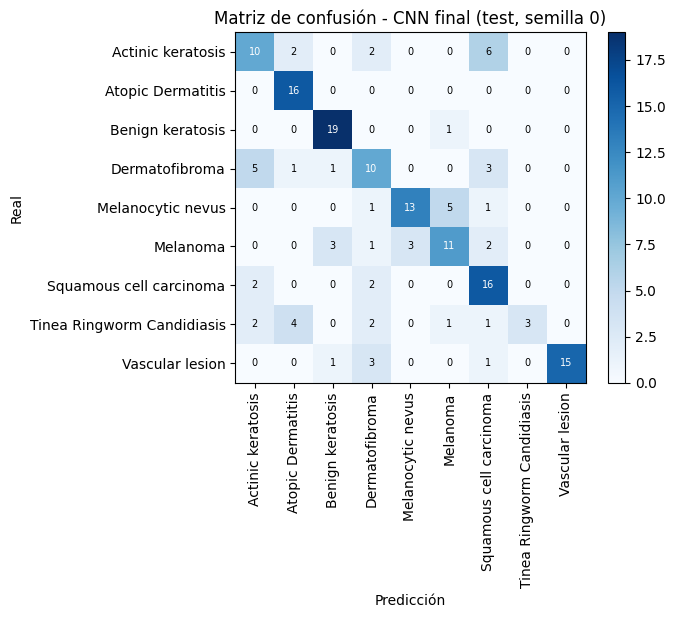

In [ ]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

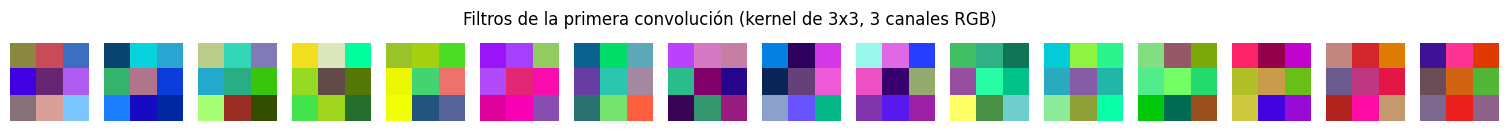

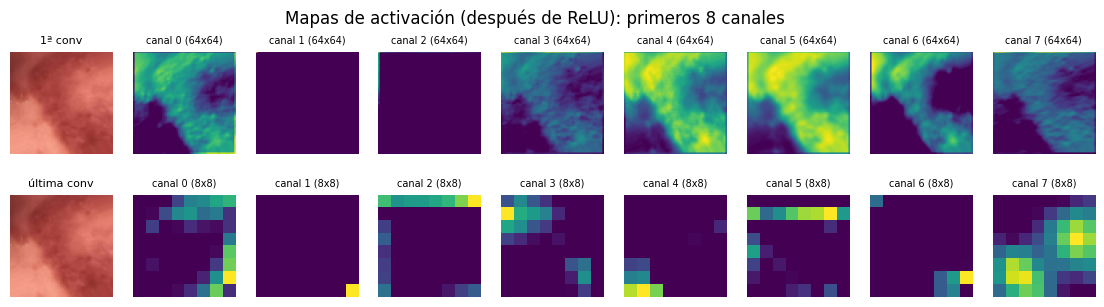

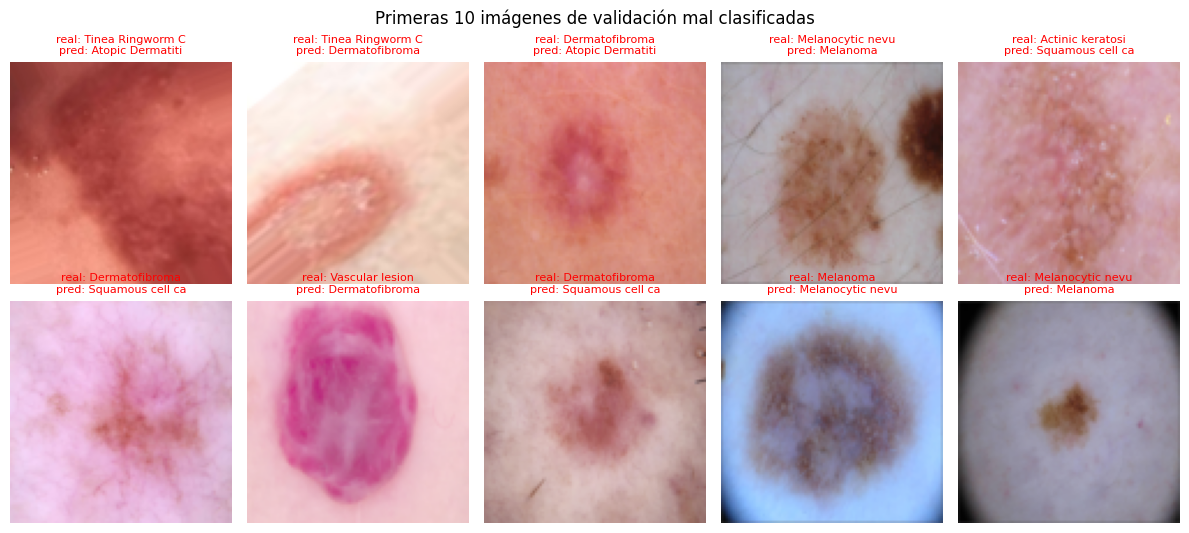

In [ ]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?

**Respuestas**

La configuración final, elegida con validación de forma greedy, es la CNN de 4 bloques con augmentation flips+rot90, que en validación obtiene 0.690 ± 0.046.

1. En test obtiene 0.677 ± 0.034 con 5 semillas, con un error estándar del test de ±0.036. La caída desde validación (−1.3 puntos) es mucho menor que ese error, por lo que el resultado es coherente. Se esperaba un sesgo optimista, porque la configuración se eligió como la mejor entre varias en validación y el 0.690 se midió sobre la misma validación usada para elegir. Sin embargo, con desvíos de 3 a 5 puntos entre semillas, ese sesgo no se distingue del ruido.

2. La comparación en test es la siguiente.

   | | Parámetros | test_acc | F1 macro | Entrenamiento |
   |---|---|---|---|---|
   | CNN final | 361.113 | 0.677 ± 0.034 | 0.666 ± 0.037 | 5.9 s |
   | MLP 64 px | 6.358.793 | 0.504 ± 0.053 | 0.487 ± 0.057 | 0.9 s |

   La CNN supera a la MLP por 17 puntos, mucho más que el error estándar y los desvíos, con 18 veces menos parámetros. Como la CNN final usa augmentation y la MLP no, esa diferencia incluye los dos efectos, aunque en validación la augmentation aportó a lo sumo 2.4 puntos y la convolución sola, 10. Tarda 6 veces más en entrenar, pero se trata de segundos, por lo que el costo está justificado.

3. En la matriz de confusión (semilla 0), las confusiones se producen entre lesiones clínica y visualmente parecidas. La más frecuente es Actinic keratosis clasificada como Squamous cell carcinoma (6 de 20), lo que es esperable porque la queratosis actínica es precursora del carcinoma escamoso y ambas son lesiones rosadas y descamativas sobre piel dañada por el sol. También se confunde Dermatofibroma con Actinic keratosis (5) y con carcinoma escamoso (3), Melanocytic nevus con Melanoma (5) y Tinea con Atopic Dermatitis (4). Tinea tiene el peor recall (0.23), con solo 3 aciertos de 13. Atopic Dermatitis alcanza un recall de 1.00 pero una precisión de 0.70, porque absorbe errores de otras clases, y es probable que aproveche el atajo detectado en el EDA (fotos clínicas de 294×222).

   No todos los errores tienen la misma gravedad. No detectar un melanoma (un falso negativo) es lo más grave, porque retrasa el tratamiento de un cáncer con riesgo de metástasis. El recall de melanoma es 0.55, ya que 9 de 20 melanomas se clasifican como otra lesión, 7 de ellos como benignas (3 queratosis benignas, 3 nevus y 1 dermatofibroma). Confundir un nevus con un melanoma (un falso positivo) solo genera una consulta o una biopsia de más. Por eso la métrica más relevante es el recall (sensibilidad) del melanoma y de las clases malignas (melanoma y carcinoma escamoso), complementado con el F1 macro para no ocultar clases mal reconocidas como Tinea. El accuracy asigna el mismo peso a todos los errores y no refleja estas diferencias.

4. Los filtros de la primera convolución (3×3) se parecen más a detectores de combinaciones de color que a detectores de bordes bien definidos, ya que con kernels tan chicos y pocas imágenes aprenden sobre todo contrastes de color. Los mapas de activación de la primera capa (64×64) conservan la forma de la imagen y separan la lesión de la piel según el tono, y algunos canales quedan en cero para esa imagen porque la ReLU está apagada. En la última capa (8×8) los mapas son gruesos y esparsos, con pocas posiciones activas, porque cada unidad resume una zona de 38 px (el campo receptivo con 4 bloques) y responde a patrones más abstractos. Las imágenes mal clasificadas son sobre todo lesiones pigmentadas oscuras (nevus y melanoma confundidos entre sí), lesiones rosadas sin estructura clara (dermatofibroma, carcinoma y queratosis actínica) y primeros planos de Tinea sin el anillo característico, que el modelo confunde con dermatitis.

5. La principal fuente de sesgo son los atajos de adquisición, ya que la resolución original y el tipo de foto dependen de la clase. Atopic Dermatitis y Tinea son fotos clínicas con fondo, y el resto son dermatoscopias de 600×450 o de ~1024×768 según la clase, con viñetas o reflejos de flash. El modelo puede reconocer el origen de la imagen en lugar de la lesión, lo que inflaría los resultados de algunas clases. Además, el chequeo de duplicados compara archivos idénticos (MD5) y miniaturas casi iguales (hash perceptual), y ninguno de los dos detecta una copia rotada o espejada de la misma imagen, por lo que, si el dataset original incluyera copias aumentadas, podrían quedar en splits distintos y filtrar información. El dataset es chico (506 imágenes de train, 169 de validación y 169 de test, con errores estándar de ±3.6 puntos), se usa una sola partición, se decide con 3 semillas y se evalúa con 5, y a eso se suma la variación por el no determinismo de la GPU. Con más tiempo convendría usar validación cruzada o varias particiones, incorporar más imágenes (el ISIC completo), aplicar transfer learning desde una red preentrenada, separar o estandarizar las fuentes (recortando a la lesión y unificando la resolución) para eliminar los atajos, y usar pesos por clase con un umbral que priorice la sensibilidad para el melanoma.

## Declaración de uso de IA

Se utilizó Claude (Anthropic) como herramienta de asistencia durante el desarrollo del presente trabajo práctico. Principalmente, se recurrió a la herramienta para mejorar la redacción de las explicaciones, organizar los análisis y revisar la claridad y coherencia de los contenidos presentados.

También se utilizó como apoyo para consultar conceptos teóricos relacionados con los temas abordados, revisar la implementación de algunos procedimientos, verificar la consistencia de los análisis y discutir la interpretación de los resultados obtenidos.

La herramienta fue utilizada como complemento del proceso de trabajo, especialmente en las instancias de revisión, corrección y elaboración de las explicaciones y conclusiones.